# LoadLens: business summary

**Question.** A facility manager runs a portfolio of buildings. Can a forecast of tomorrow's hourly
electricity use beat the rule of thumb ("same as this hour last week") by enough to matter for
energy purchasing and peak-demand planning?

**Data.** 10 real buildings at one Washington, DC site from the Building Data Genome Project 2
(hourly meters, 2016-2017) with real hourly weather from Open-Meteo.

**Test.** The model is trained on the earlier data, then makes recursive 48-hour forecasts from
about 20 start dates per building across the held-out autumn-winter 2017 period (about 200 forecasts).
Each forecast only sees data from before its start date, as it would in production. Run
`make backtest report` to regenerate everything below.

In [1]:
import json
import pandas as pd
from IPython.display import Image, Markdown, display

bt = json.load(open('../reports/backtest_metrics.json'))
biz = json.load(open('../reports/business_metrics.json'))
pd.set_option('display.precision', 1)

## 1. Headline result

- **Forecast error (WAPE): 8.2% for the model vs 12.8% for the naive baseline**, over 200 forecasts of 48 h across 10 buildings.
- 95% bootstrap interval for the improvement: **3.5 to 5.7 percentage points** (resampling whole forecasts, 2000 draws).
- The model beats the baseline on **10 of 10** buildings.
- 33 forecast hours were not scored because the meter itself had failed.

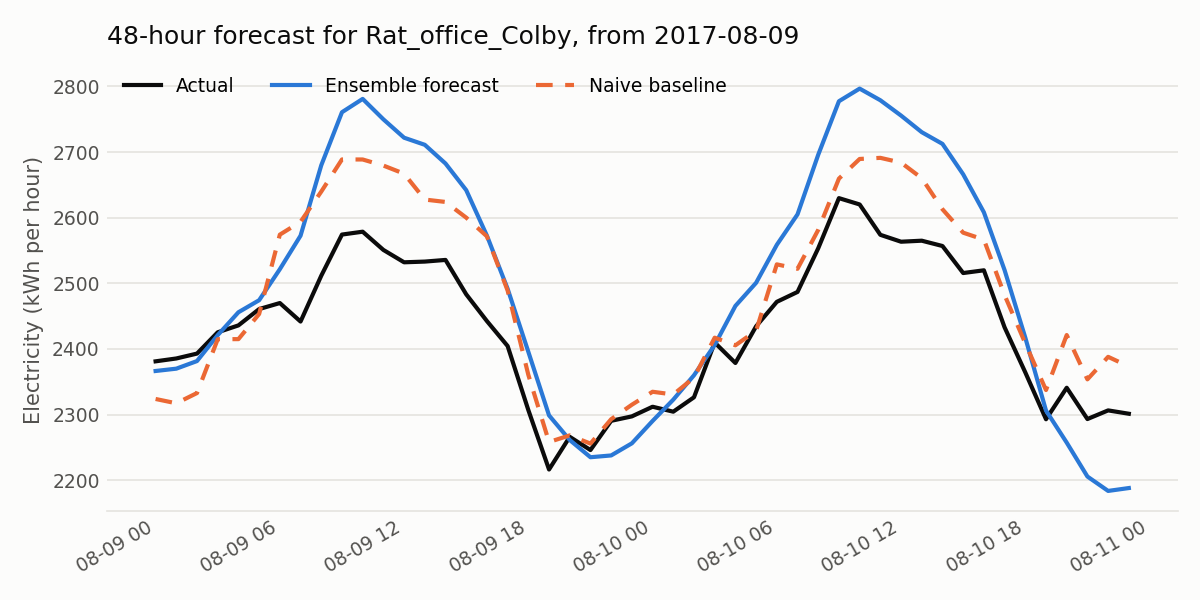

In [2]:
lo, hi = bt['improvement_points_ci95']
display(Markdown(
    f"- **Forecast error (WAPE): {bt['ensemble_wape']:.1f}% for the model vs {bt['naive_wape']:.1f}% "
    f"for the naive baseline**, over {bt['n_forecasts']} forecasts of {bt['horizon_hours']} h "
    f"across {bt['n_buildings']} buildings.\n"
    f"- 95% bootstrap interval for the improvement: **{lo:.1f} to {hi:.1f} percentage points** "
    f"(resampling whole forecasts, {bt['n_boot']} draws).\n"
    f"- The model beats the baseline on **{bt['buildings_beating_naive']} of {bt['n_buildings']}** buildings.\n"
    f"- {bt['excluded_meter_outage_hours']} forecast hours were not scored because the meter itself had failed."
))
Image('../reports/figures/example_forecast.png')

## 2. The data-quality finding

The first version of this backtest made the model look barely better than the rule of thumb
(12.9% vs 13.5% WAPE, interval crossing zero). Error analysis showed why: a few forecasts
were off by 50-90%, and they all started on the **same dates in different buildings**.

The cause was in the data, not the model. Four buildings' meters drop to near zero at the same
hour and recover together days later, 17 days in 2017: a shared data-logger outage. The model
trusted the broken recent readings and forecast an empty building. The naive baseline looks a
full week back and skipped the outage by luck.

**Fix** (`src/data/quality.py`): flag a reading as an outage when it is below 5% of the
building's trailing 4-week median, repair it from the same hour a week earlier before it reaches
the model, never train on it, and never score a forecast against it. That is the step a real
deployment needs anyway, since meter feeds fail.

## 3. Where the model is strong and where it fails

In [3]:
by_building = pd.DataFrame(biz['breakdowns']['by_building']).set_index('building_id')
by_building['improvement_pts'] = by_building.naive_wape - by_building.ensemble_wape
by_building.sort_values('ensemble_wape')

,ensemble_wape,naive_wape,hours,improvement_pts
building_id,,,,
Rat_office_Colby,5.6,10.0,953.0,4.4
Rat_health_Tanya,9.9,18.7,960.0,8.8
Rat_education_Keith,10.0,15.6,960.0,5.6
Rat_education_Lee,10.0,13.3,960.0,3.3
Rat_education_Theo,10.7,14.5,941.0,3.8
Rat_education_Kathryn,11.0,12.7,960.0,1.7
Rat_education_Beverly,11.0,17.4,953.0,6.3
Rat_education_Kelsey,11.7,19.8,960.0,8.1
Rat_assembly_Adolfo,16.5,33.8,960.0,17.3


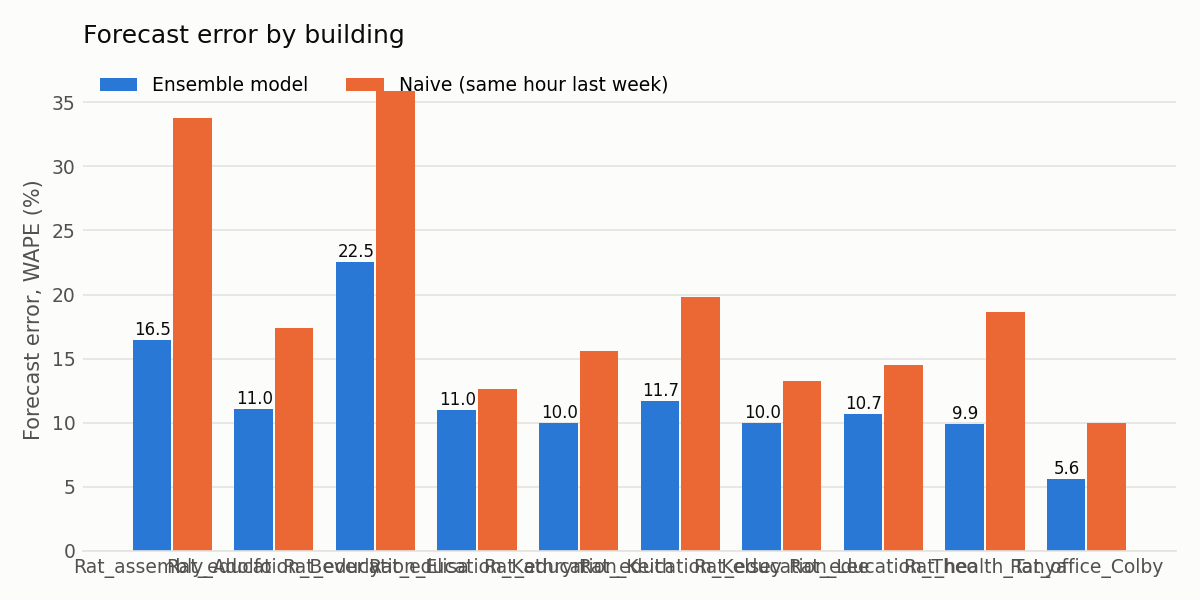

In [4]:
Image('../reports/figures/wape_by_building.png')

In [5]:
for key in ['by_forecast_day', 'by_day_type', 'by_temperature']:
    if key in biz['breakdowns']:
        display(pd.DataFrame(biz['breakdowns'][key]).set_index(pd.DataFrame(biz['breakdowns'][key]).columns[0]))

,ensemble_wape,naive_wape,hours
forecast_day,,,
day 1 (0-24 h),7.0,12.0,4797.0
day 2 (25-48 h),9.5,13.6,4770.0


,ensemble_wape,naive_wape,hours
day_type,,,
weekday,8.2,12.3,6700.0
weekend,8.3,14.0,2867.0


,ensemble_wape,naive_wape,hours
temperature_band,,,
< 5 °C,7.1,12.2,1814.0
5-15 °C,8.2,12.9,3103.0
15-25 °C,8.6,13.1,3760.0
> 25 °C,8.6,11.9,890.0


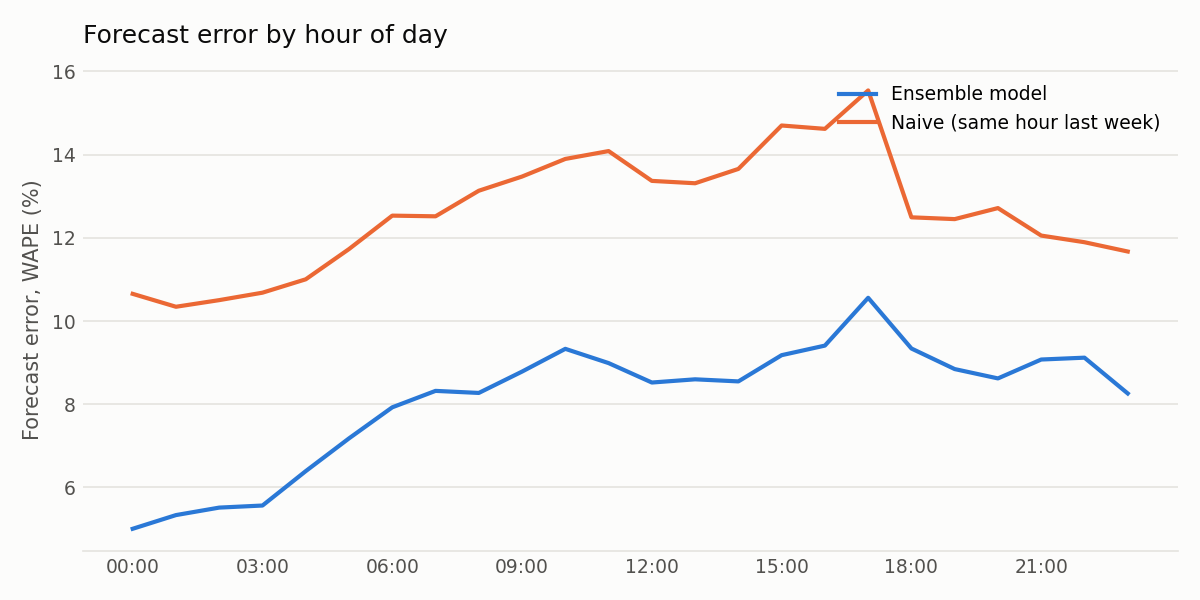

In [6]:
Image('../reports/figures/wape_by_hour.png')

## 4. Does it find the daily peak?

In [7]:
p = biz['peak_detection']
display(Markdown(
    f"Over {p['building_days']} building-days, the forecast puts the daily peak within one hour of the real "
    f"peak **{p['peak_hour_hit_rate_pct']['ensemble']}%** of the time (baseline "
    f"{p['peak_hour_hit_rate_pct']['naive']}%). Median error in the peak's size: "
    f"**{p['median_peak_size_error_pct']['ensemble']}%** (baseline {p['median_peak_size_error_pct']['naive']}%).\n\n"
    "Peak demand sets demand charges, so a facility manager would act on this, for example to "
    "pre-cool before the peak or shift flexible load. The honest reading: the model is only modestly "
    "better at the exact peak *hour*, because these buildings run on a flat daytime plateau (on about "
    "half of the days, an hour more than an hour away from the peak is within 3% of it). Its clearer "
    "advantage is the peak's *size* and the total energy."
))

Over 393 building-days, the forecast puts the daily peak within one hour of the real peak **37.9%** of the time (baseline 33.8%). Median error in the peak's size: **9.7%** (baseline 11.6%).

Peak demand sets demand charges, so a facility manager would act on this, for example to pre-cool before the peak or shift flexible load. The honest reading: the model is only modestly better at the exact peak *hour*, because these buildings run on a flat daytime plateau (on about half of the days, an hour more than an hour away from the peak is within 3% of it). Its clearer advantage is the peak's *size* and the total energy.

## 5. What the error is worth (scenario, not a measurement)

If energy is bought ahead of time based on the forecast, every kWh of error is settled at a
worse price. The kWh of error below are **measured** in the backtest; the price per kWh of error
is an **assumption**, shown as a range.

In [8]:
c = biz['cost_scenario']
display(Markdown(
    f"Average absolute error per building-hour: **{c['mean_abs_error_kwh_per_hour']['ensemble']} kWh** "
    f"(model) vs **{c['mean_abs_error_kwh_per_hour']['naive']} kWh** (baseline), i.e. about "
    f"**{c['annual_error_kwh_avoided_per_building']:,} kWh** less error per building per year."
))
pd.DataFrame(c['scenarios']).rename(columns={
    'price_usd_per_kwh_error': 'Assumed $ per kWh of error',
    'annual_cost_per_building_ensemble': 'Annual error cost / building, model ($)',
    'annual_cost_per_building_naive': 'Annual error cost / building, baseline ($)',
    'annual_saving_per_building': 'Saving / building ($)',
    'annual_saving_portfolio': f"Saving, {c['n_buildings']}-building portfolio ($)",
})

Average absolute error per building-hour: **36.48 kWh** (model) vs **56.59 kWh** (baseline), i.e. about **176,133 kWh** less error per building per year.

,Assumed $ per kWh of error,"Annual error cost / building, model ($)","Annual error cost / building, baseline ($)",Saving / building ($),"Saving, 10-building portfolio ($)"
0,2.0e-02,6392,9914,3523,35227
1,5.0e-02,15980,24786,8807,88066
2,1.0e-01,31959,49572,17613,176133


## 6. What drives the forecast (SHAP)

,feature,mean_abs_shap
0,energy_consumption_kwh_lag_1,1.5e-01
1,energy_consumption_kwh_lag_24,4.0e-02
2,energy_consumption_kwh_lag_168,3.0e-02
3,hour_cos,1.5e-02
4,hour_sin,1.3e-02
5,energy_consumption_kwh_rolling_mean_24,1.1e-02
6,day_of_week,8.2e-03
7,hour,8.2e-03
8,is_business_hour,6.7e-03
9,day_sin,6.3e-03


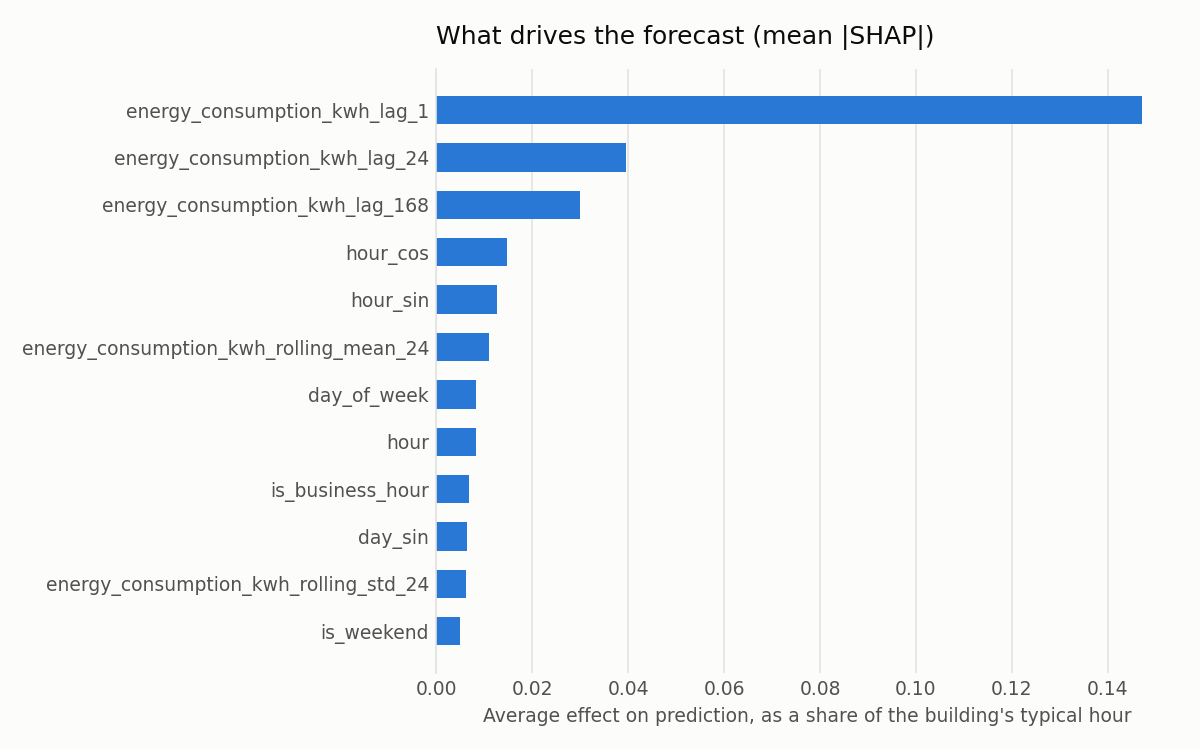

In [9]:
display(pd.DataFrame(biz['top_drivers']))
Image('../reports/figures/shap_importance.png')

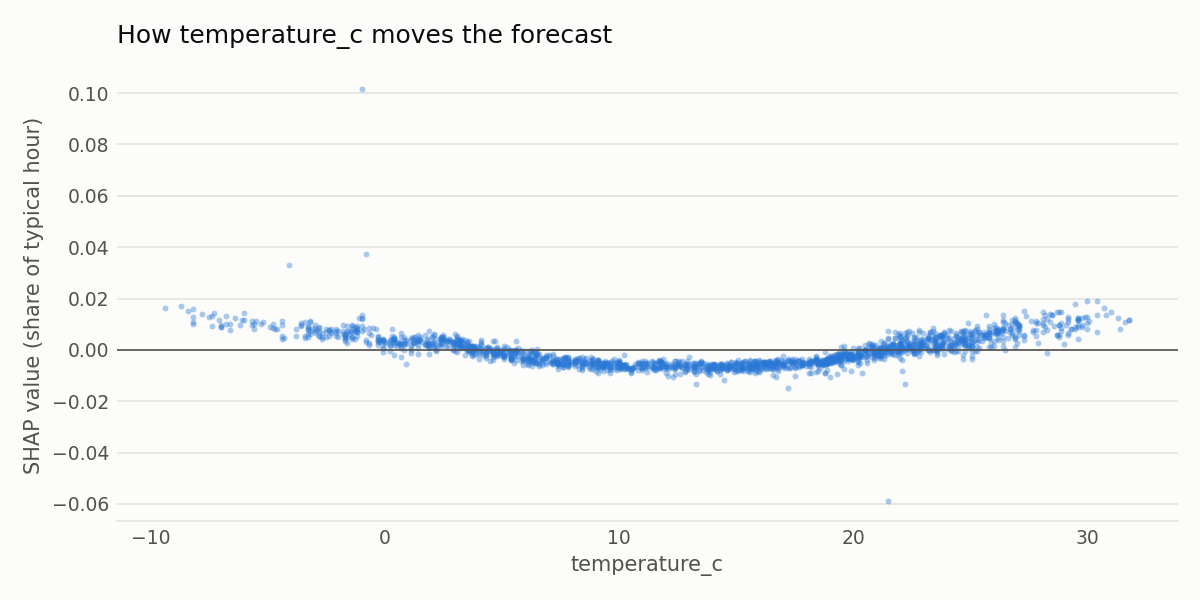

In [10]:
import os
if os.path.exists('../reports/figures/shap_temperature.png'):
    display(Image('../reports/figures/shap_temperature.png'))

SHAP values are in units of the building's typical hour, because the model predicts consumption
relative to each building's previous-week average. That is also why one model can serve buildings
whose sizes differ by 100x.

## 7. Recommendation

1. **Use the model for day-ahead purchasing and peak planning** in buildings where it clearly beats
   the baseline (table in section 3); keep the rule of thumb as a fallback where it does not.
2. **Put the meter-outage check in front of any forecast.** It was the single largest source of error,
   and it costs nothing to run.
3. **Before acting on the savings estimate**, replace the assumed price of error with the site's real
   tariff and balancing costs; the kWh figures carry over unchanged.
4. **Next model improvement:** holiday and academic-calendar features. Seven of the ten buildings
   are education buildings, whose use follows term dates the model currently has no feature for.